# Experiment 3: Decision Tree, Bagging, and Boosting
**Case Study:** Loan Approval Classification based on Income and Credit Score (12-row assumed dataset)

NOTE: Your Experiment 3 title m Random Forest(Bagging), while Step 6 uses BaggingClassifier. If your examiner asks specifically for RandomForestClassifier, you can swap BaggingClassifier with:
from sklearn.ensemble import RandomForestClassifier
bag_model = RandomForestClassifier(n_estimators=50, criterion='gini', random_state=42)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

### Step 1 & 2: Create Assumed Dataset (12 Rows) & Train-Test Split

In [2]:
# Assumed Dataset: Predict Loan Approval (0 = Rejected, 1 = Approved)
data = {
    'Income_Lakhs': [2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 6.0, 7.5, 8.0, 9.0, 10.0, 12.0],
    'Credit_Score': [550, 580, 600, 620, 690, 640, 710, 680, 750, 780, 800, 820],
    'Loan_Approved': [0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1]
}

df = pd.DataFrame(data)
print("--- Assumed Dataset (12 Rows) ---")
print(df.to_string(index=False))

X = df[['Income_Lakhs', 'Credit_Score']]
y = df['Loan_Approved']
target_names = ['Rejected (0)', 'Approved (1)']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)
print(f"\nTraining samples: {len(X_train)} | Testing samples: {len(X_test)}")

--- Assumed Dataset (12 Rows) ---
 Income_Lakhs  Credit_Score  Loan_Approved
          2.5           550              0
          3.0           580              0
          3.5           600              0
          4.0           620              0
          4.5           690              1
          5.0           640              0
          6.0           710              1
          7.5           680              0
          8.0           750              1
          9.0           780              1
         10.0           800              1
         12.0           820              1

Training samples: 8 | Testing samples: 4


### Step 3: Implement Decision Tree using Gini Index (Deliverable 2a)

Decision Tree Performance
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

Classification Report:
              precision    recall  f1-score   support

Rejected (0)       1.00      1.00      1.00         2
Approved (1)       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4

Decision Tree Confusion Matrix:
 [[2 0]
 [0 2]]


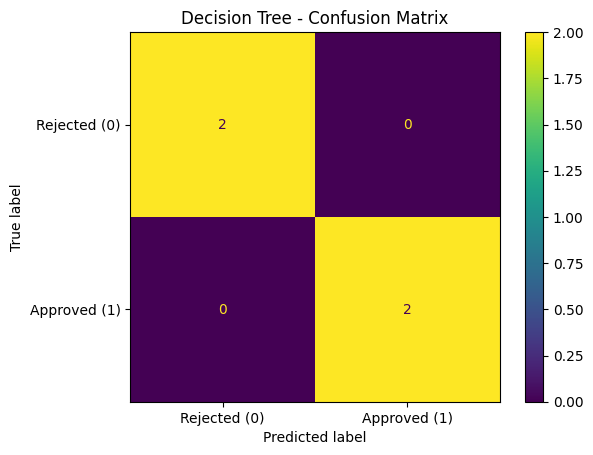

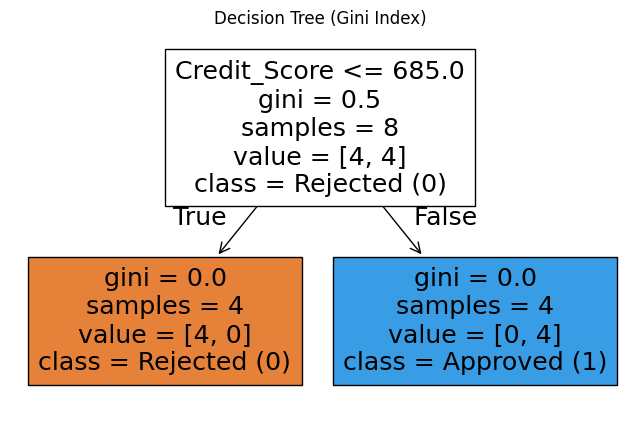

In [3]:
dt_model = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, average='weighted', zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, average='weighted', zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, average='weighted', zero_division=0)

print('Decision Tree Performance')
print(f'Accuracy : {dt_accuracy:.4f}')
print(f'Precision: {dt_precision:.4f}')
print(f'Recall   : {dt_recall:.4f}')
print(f'F1-score : {dt_f1:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_dt, target_names=target_names, zero_division=0))

cm_dt = confusion_matrix(y_test, y_pred_dt)
print('Decision Tree Confusion Matrix:\n', cm_dt)
ConfusionMatrixDisplay(cm_dt, display_labels=target_names).plot(cmap='viridis')
plt.title('Decision Tree - Confusion Matrix')
plt.show()

plt.figure(figsize=(8, 5))
plot_tree(dt_model, feature_names=X.columns, class_names=target_names, filled=True)
plt.title('Decision Tree (Gini Index)')
plt.show()

### Step 4 & 5: Apply Boosting (AdaBoost) & Compare with Decision Tree (Deliverables 2b & 2c)

AdaBoost Performance
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

Classification Report:
              precision    recall  f1-score   support

Rejected (0)       1.00      1.00      1.00         2
Approved (1)       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4

Boosting vs Non-Boosting Model
----------------------------------------
Decision Tree Accuracy: 1.0000
AdaBoost Accuracy     : 1.0000


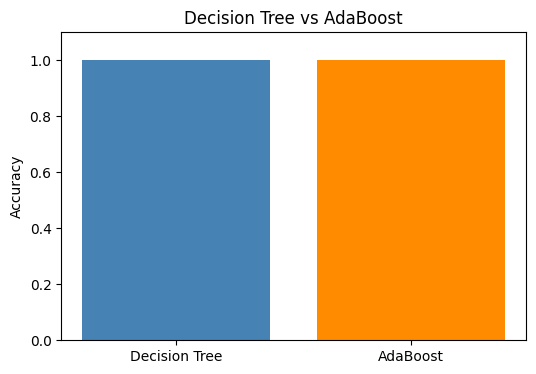

In [4]:
boost_model = AdaBoostClassifier(n_estimators=50, learning_rate=0.5, random_state=42)
boost_model.fit(X_train, y_train)
y_pred_boost = boost_model.predict(X_test)

boost_accuracy = accuracy_score(y_test, y_pred_boost)
boost_precision = precision_score(y_test, y_pred_boost, average='weighted', zero_division=0)
boost_recall = recall_score(y_test, y_pred_boost, average='weighted', zero_division=0)
boost_f1 = f1_score(y_test, y_pred_boost, average='weighted', zero_division=0)

print('AdaBoost Performance')
print(f'Accuracy : {boost_accuracy:.4f}')
print(f'Precision: {boost_precision:.4f}')
print(f'Recall   : {boost_recall:.4f}')
print(f'F1-score : {boost_f1:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_boost, target_names=target_names, zero_division=0))

print('Boosting vs Non-Boosting Model')
print('-' * 40)
print(f'Decision Tree Accuracy: {dt_accuracy:.4f}')
print(f'AdaBoost Accuracy     : {boost_accuracy:.4f}')

plt.figure(figsize=(6, 4))
plt.bar(['Decision Tree', 'AdaBoost'], [dt_accuracy, boost_accuracy], color=['steelblue', 'darkorange'])
plt.ylim(0, 1.1)
plt.ylabel('Accuracy')
plt.title('Decision Tree vs AdaBoost')
plt.show()

### Step 6 & 7: Apply Bagging & Compare with Decision Tree (Deliverables 2d & 2e)

Bagging Performance
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

Classification Report:
              precision    recall  f1-score   support

Rejected (0)       1.00      1.00      1.00         2
Approved (1)       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4

Bagging Confusion Matrix:
 [[2 0]
 [0 2]]


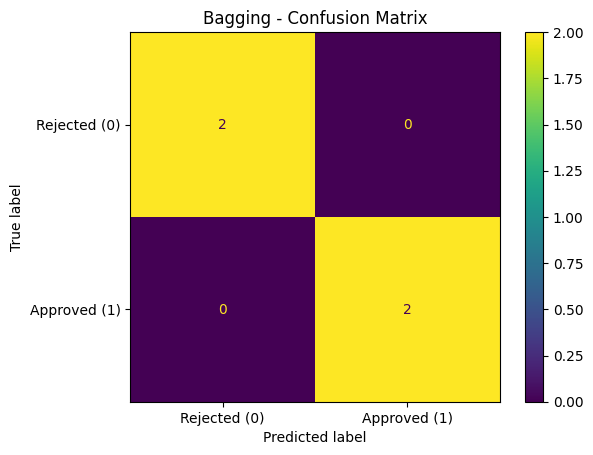

Bagging vs Non-Bagging Model
----------------------------------------
Decision Tree Accuracy: 1.0000
Bagging Accuracy      : 1.0000


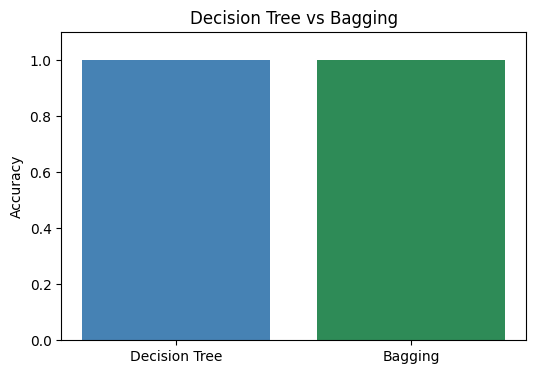

In [5]:
bag_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50,
    random_state=42
)
bag_model.fit(X_train, y_train)
y_pred_bag = bag_model.predict(X_test)

bag_accuracy = accuracy_score(y_test, y_pred_bag)
bag_precision = precision_score(y_test, y_pred_bag, average='weighted', zero_division=0)
bag_recall = recall_score(y_test, y_pred_bag, average='weighted', zero_division=0)
bag_f1 = f1_score(y_test, y_pred_bag, average='weighted', zero_division=0)

print('Bagging Performance')
print(f'Accuracy : {bag_accuracy:.4f}')
print(f'Precision: {bag_precision:.4f}')
print(f'Recall   : {bag_recall:.4f}')
print(f'F1-score : {bag_f1:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_bag, target_names=target_names, zero_division=0))

cm_bag = confusion_matrix(y_test, y_pred_bag)
print('Bagging Confusion Matrix:\n', cm_bag)
ConfusionMatrixDisplay(cm_bag, display_labels=target_names).plot(cmap='viridis')
plt.title('Bagging - Confusion Matrix')
plt.show()

print('Bagging vs Non-Bagging Model')
print('-' * 40)
print(f'Decision Tree Accuracy: {dt_accuracy:.4f}')
print(f'Bagging Accuracy      : {bag_accuracy:.4f}')

plt.figure(figsize=(6, 4))
plt.bar(['Decision Tree', 'Bagging'], [dt_accuracy, bag_accuracy], color=['steelblue', 'seagreen'])
plt.ylim(0, 1.1)
plt.ylabel('Accuracy')
plt.title('Decision Tree vs Bagging')
plt.show()

### Step 8: Overall Model Comparison (Deliverable 3)

        Model  Accuracy  Precision  Recall  F1-Score
Decision Tree       1.0        1.0     1.0       1.0
     AdaBoost       1.0        1.0     1.0       1.0
      Bagging       1.0        1.0     1.0       1.0


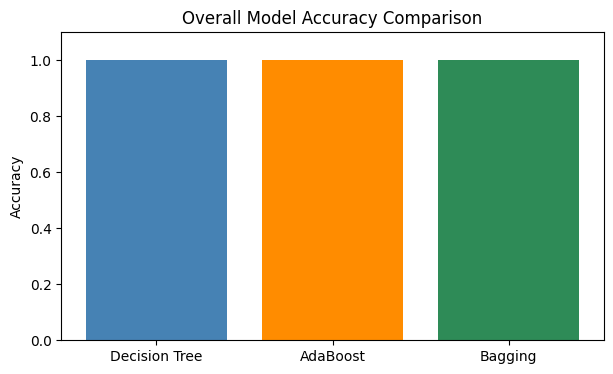

In [6]:
results = pd.DataFrame({
    'Model': ['Decision Tree', 'AdaBoost', 'Bagging'],
    'Accuracy': [dt_accuracy, boost_accuracy, bag_accuracy],
    'Precision': [dt_precision, boost_precision, bag_precision],
    'Recall': [dt_recall, boost_recall, bag_recall],
    'F1-Score': [dt_f1, boost_f1, bag_f1]
})

print(results.round(4).to_string(index=False))

plt.figure(figsize=(7, 4))
plt.bar(results['Model'], results['Accuracy'], color=['steelblue', 'darkorange', 'seagreen'])
plt.ylim(0, 1.1)
plt.ylabel('Accuracy')
plt.title('Overall Model Accuracy Comparison')
plt.show()